# 🤖 Klasifikasi Multinomial Naive Bayes

**Nama :** Fadhli Ilham Nafi'an Yuswono (23.18.001)
**Jurusan :** Teknik Informatika S-1 — Institut Teknologi Nasional Malang
**Penelitian :** Nafinder — Rekomendasi Kafe WFC Kota Malang dengan Multinomial Naive Bayes

**Metode :** Multinomial Naive Bayes (TF-IDF + RandomOverSampler)
**Input :** `dataset_preprocessed.csv` (hasil notebook preprocessing)
**Output :** `evaluasi_mnb.json`, `confusion_matrix.csv`, `confusion_matrix.png`, `metrik_per_kelas.png`, `perbandingan_mnb.csv`

Tahapan: load data → hapus duplikat → split anti-bocor per `review_id` → TF-IDF + ROS + MNB → evaluasi → simpan hasil → perbandingan konfigurasi.


## ⚙️ IMPORT LIBRARY & SETUP ENVIRONMENT

In [1]:
import json
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

def ribu(n):
    """Format angka gaya Indonesia: 109.778"""
    return f"{n:,}".replace(",", ".")

def simpan(fig, nama):
    """Simpan dan unduh grafik di sel yang sama."""
    fig.savefig(nama, bbox_inches="tight")
    try:
        files.download(nama)
    except Exception as e:
        print("Download dilewati (bukan Colab):", e)

KOL_GRUP = "review_id"
KOL_TEKS = "teks_preprocessed"
KOL_ASPEK = "aspek"
KOL_LABEL = "sentimen"

print("✅ Libraries imported successfully!")


✅ Libraries imported successfully!


## 📥 LOAD DATASET

In [2]:
uploaded = files.upload()
nama = list(uploaded.keys())[0]
assert nama == "dataset_preprocessed.csv", f"Upload dataset_preprocessed.csv, bukan {nama!r}"
df = pd.read_csv(nama, encoding="utf-8-sig")

for k in ["review_id", "sub_kalimat", "aspek", "sentimen", "teks_preprocessed", "kafe_id"]:
    assert k in df.columns, f"Kolom wajib {k!r} tidak ditemukan"

print(f"✅ Dataset loaded successfully!")
print(f"📊 Data: {len(df):,} label | {df['review_id'].nunique():,} review unik | {df['kafe_id'].nunique()} kafe")
print("\nDistribusi aspek:")
display(df["aspek"].value_counts().to_frame("Jumlah"))
print("Distribusi sentimen:")
display(df["sentimen"].value_counts().to_frame("Jumlah"))


Saving dataset_preprocessed.csv to dataset_preprocessed.csv
✅ Dataset loaded successfully!
📊 Data: 240,636 label | 88,189 review unik | 323 kafe

Distribusi aspek:


,Jumlah
aspek,
makanan_minuman,86334
suasana,76219
pelayanan,28070
harga,23347
fasilitas_wfc,17335
kebersihan,9331


Distribusi sentimen:


,Jumlah
sentimen,
positif,197658
netral,23058
negatif,19920


## 🧹 HAPUS DUPLIKAT

In [3]:
# Hapus observasi identik dalam review yang sama
sebelum = len(df)
df = df.drop_duplicates(
    subset=[KOL_GRUP, KOL_TEKS, KOL_ASPEK, KOL_LABEL]
).reset_index(drop=True)
print(f"📊 Observasi duplikat dibuang: {sebelum - len(df):,}")
print(f"📊 Data bersih: {len(df):,} label | {df[KOL_GRUP].nunique():,} review")


📊 Observasi duplikat dibuang: 34
📊 Data bersih: 240,602 label | 88,189 review


## ✂️ PEMBAGIAN DATA TRAINING & TESTING

Pembagian berbasis `review_id`, lalu teks preprocessing yang juga terdapat di testing dikeluarkan dari testing agar tidak ada kebocoran data.


In [4]:
from sklearn.model_selection import GroupShuffleSplit

RASIO_TEST = 0.2
RANDOM_STATE = 42

# Satu review_id hanya dialokasikan ke satu sisi
splitter = GroupShuffleSplit(n_splits=1, test_size=RASIO_TEST, random_state=RANDOM_STATE)
idx_train, idx_test = next(splitter.split(df, groups=df[KOL_GRUP]))
train = df.iloc[idx_train].reset_index(drop=True)
test = df.iloc[idx_test].reset_index(drop=True)

# Singkirkan dari testing teks yang juga terdapat pada training
teks_latih = set(train[KOL_TEKS])
sebelum_filter = len(test)
test = test[~test[KOL_TEKS].isin(teks_latih)].reset_index(drop=True)
baris_test_dibuang = sebelum_filter - len(test)

set_train = set(train[KOL_GRUP])
set_test = set(test[KOL_GRUP])

print(f"📊 Baris testing dibuang karena teks identik: {ribu(baris_test_dibuang)}")
print(f"📊 Data training : {ribu(len(train))} label | {ribu(len(set_train))} review")
print(f"📊 Data testing  : {ribu(len(test))} label | {ribu(len(set_test))} review")
print(f"📊 Proporsi label aktual: training {len(train)/len(df):.1%} | testing {len(test)/len(df):.1%}")

assert len(train) > 0 and len(test) > 0, "Training atau testing kosong"
assert set_train.isdisjoint(set_test), "Review bocor antar split"
assert set(train[KOL_TEKS]).isdisjoint(set(test[KOL_TEKS])), "Teks bocor antar split"
assert set(test[KOL_LABEL]) == set(df[KOL_LABEL]), "Ada kelas sentimen yang tidak terwakili di testing"
print("✅ Validasi anti-bocor per review_id dan teks: lolos")

print("\nDistribusi sentimen per aspek pada data testing (%):")
rasio_test = pd.crosstab(test[KOL_ASPEK], test[KOL_LABEL], normalize="index") * 100
display(rasio_test.round(1))


📊 Baris testing dibuang karena teks identik: 10.713
📊 Data training : 192.341 label | 70.551 review
📊 Data testing  : 37.548 label | 14.930 review
📊 Proporsi label aktual: training 79.9% | testing 15.6%
✅ Validasi anti-bocor per review_id dan teks: lolos

Distribusi sentimen per aspek pada data testing (%):


sentimen,negatif,netral,positif
aspek,,,
fasilitas_wfc,12.5,12.5,75.1
harga,10.4,9.8,79.8
kebersihan,16.7,11.6,71.7
makanan_minuman,8.9,11.9,79.2
pelayanan,18.8,8.7,72.5
suasana,6.2,8.7,85.1


### 📐 TF-IDF + RandomOverSampler + Multinomial Naive Bayes

Konfigurasi baseline: TF-IDF dengan sublinear TF dan smooth IDF, RandomOverSampler hanya pada training setelah TF-IDF, lalu Multinomial Naive Bayes dengan alpha 1.

$$P(c) = \frac{N_c}{N}, \qquad P(t \mid c) = \frac{n_{tc} + \alpha}{n_c + \alpha V}$$


In [5]:
!pip install -q imbalanced-learn

from collections import Counter
from imblearn.over_sampling import RandomOverSampler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

tfidf = TfidfVectorizer(lowercase=True, sublinear_tf=True, smooth_idf=True,
                        token_pattern=r"(?u)\b\w\w+\b")
X_train = tfidf.fit_transform(train[KOL_TEKS])
X_test = tfidf.transform(test[KOL_TEKS])
print(f"📊 Training: {X_train.shape} | Testing: {X_test.shape}")
print(f"📊 Kosakata: {ribu(len(tfidf.vocabulary_))}")

print("Sebelum ROS:", dict(Counter(train[KOL_LABEL])))
ros = RandomOverSampler(random_state=RANDOM_STATE)
X_train_ros, y_train_ros = ros.fit_resample(X_train, train[KOL_LABEL].values)
print("Sesudah ROS:", dict(Counter(y_train_ros)))
print("Testing    :", dict(Counter(test[KOL_LABEL])))

clf = MultinomialNB(alpha=1.0)
clf.fit(X_train_ros, y_train_ros)
y_pred = clf.predict(X_test)
print("✅ Baseline selesai dilatih | kelas:", list(clf.classes_))


📊 Training: (192341, 25761) | Testing: (37548, 25761)
📊 Kosakata: 25.761
Sebelum ROS: {'netral': 18603, 'positif': 157879, 'negatif': 15859}
Sesudah ROS: {'netral': 157879, 'positif': 157879, 'negatif': 157879}
Testing    : {'positif': 29880, 'netral': 3919, 'negatif': 3749}
✅ Baseline selesai dilatih | kelas: [np.str_('negatif'), np.str_('netral'), np.str_('positif')]


## 📈 EVALUASI BASELINE

In [6]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

acc = accuracy_score(test[KOL_LABEL], y_pred)
p, r, f1, sup = precision_recall_fscore_support(test[KOL_LABEL], y_pred, labels=clf.classes_)
pm, rm, fm, _ = precision_recall_fscore_support(test[KOL_LABEL], y_pred, average="macro")
pw, rw, fw, _ = precision_recall_fscore_support(test[KOL_LABEL], y_pred, average="weighted")

print(f"🎯 Tingkat Akurasi Model MNB: {acc * 100:.2f}%\n")
print("📋 Classification Report:")
print(classification_report(test[KOL_LABEL], y_pred))
print(f"Macro-average    precision={pm:.4f} | recall={rm:.4f} | F1={fm:.4f}")
print(f"Weighted-average precision={pw:.4f} | recall={rw:.4f} | F1={fw:.4f}")


🎯 Tingkat Akurasi Model MNB: 69.83%

📋 Classification Report:
              precision    recall  f1-score   support

     negatif       0.41      0.70      0.52      3749
      netral       0.24      0.53      0.33      3919
     positif       0.96      0.72      0.82     29880

    accuracy                           0.70     37548
   macro avg       0.54      0.65      0.56     37548
weighted avg       0.83      0.70      0.74     37548

Macro-average    precision=0.5355 | recall=0.6503 | F1=0.5566
Weighted-average precision=0.8267 | recall=0.6983 | F1=0.7398


### 📊 1. CONFUSION MATRIX

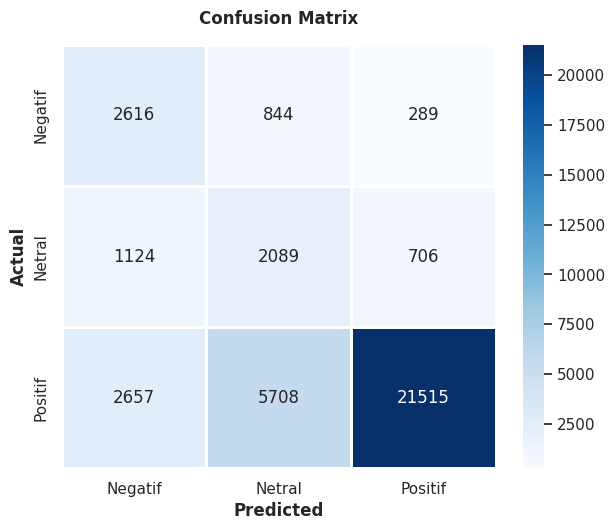

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
cm = confusion_matrix(test[KOL_LABEL], y_pred, labels=clf.classes_)

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(pd.DataFrame(cm,
                         index=[c.capitalize() for c in clf.classes_],
                         columns=[c.capitalize() for c in clf.classes_]),
            annot=True, fmt="d", cmap="Blues", linewidths=1, ax=ax)
ax.set_xlabel("Predicted", fontweight="bold")
ax.set_ylabel("Actual", fontweight="bold")
ax.set_title("Confusion Matrix", fontweight="bold", pad=15)
plt.show()
simpan(fig, "confusion_matrix.png")


### 📊 2. PRECISION, RECALL & F1-SCORE PER KELAS

,Precision,Recall,F1-Score,Support
Negatif,0.4089,0.6978,0.5157,3749
Netral,0.2418,0.5330,0.3326,3919
Positif,0.9558,0.7200,0.8213,29880


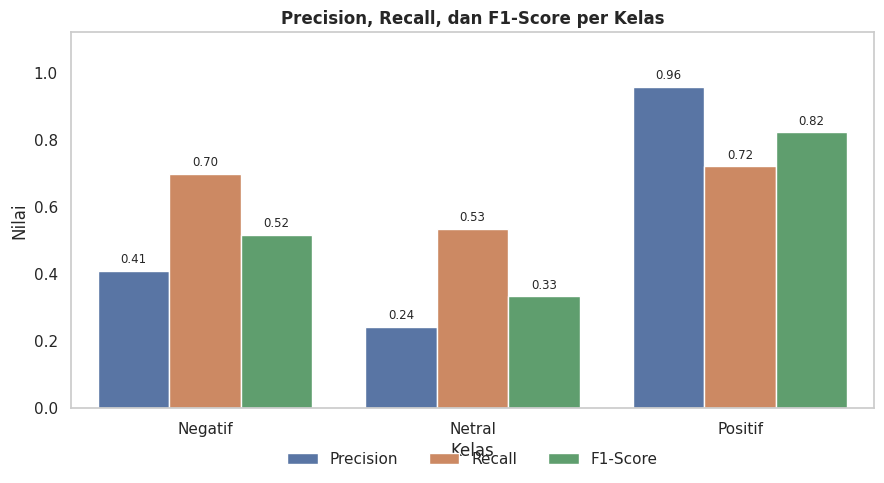

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
metrik = pd.DataFrame({
    "Precision": p, "Recall": r, "F1-Score": f1, "Support": sup
}, index=[c.capitalize() for c in clf.classes_])
display(metrik.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
metrik_plot = metrik[["Precision", "Recall", "F1-Score"]].reset_index().melt(
    id_vars="index", var_name="Metrik", value_name="Nilai").rename(columns={"index": "Kelas"})

sns.barplot(data=metrik_plot, x="Kelas", y="Nilai", hue="Metrik", ax=ax)
for b in ax.patches:
    h = b.get_height()
    if h > 0:
        ax.text(b.get_x() + b.get_width()/2, h + 0.015, f"{h:.2f}",
                ha="center", va="bottom", fontsize=8.5)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Nilai")
ax.set_title("Precision, Recall, dan F1-Score per Kelas", fontweight="bold")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08))
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
simpan(fig, "metrik_per_kelas.png")


## 💾 SIMPAN HASIL BASELINE

In [9]:
hasil = {
    "split_unit": "review_id",
    "jumlah_review_training": int(len(set_train)),
    "jumlah_review_testing": int(len(set_test)),
    "jumlah_label_training": int(len(train)),
    "jumlah_label_testing": int(len(test)),
    "baris_testing_dikeluarkan_teks_identik": int(baris_test_dibuang),
    "proporsi_testing_akhir": round(float(len(test) / len(df)), 6),
    "jumlah_training_ros": int(len(y_train_ros)),
    "kosakata_tfidf": int(len(tfidf.vocabulary_)),
    "accuracy": round(float(acc), 6),
    "precision_macro": round(float(pm), 6), "recall_macro": round(float(rm), 6), "f1_macro": round(float(fm), 6),
    "precision_weighted": round(float(pw), 6), "recall_weighted": round(float(rw), 6), "f1_weighted": round(float(fw), 6),
    "per_kelas": {lab: {"precision": round(float(pp), 6), "recall": round(float(rr), 6),
                        "f1": round(float(ff), 6), "support": int(ss)}
                  for lab, pp, rr, ff, ss in zip(clf.classes_, p, r, f1, sup)},
    "confusion_matrix": cm.tolist(),
    "kelas_urut": list(clf.classes_),
}
with open("evaluasi_mnb.json", "w", encoding="utf-8") as f:
    json.dump(hasil, f, indent=2, ensure_ascii=False)
pd.DataFrame(cm, index=clf.classes_, columns=clf.classes_).to_csv("confusion_matrix.csv")

print("✅ Tersimpan: evaluasi_mnb.json dan confusion_matrix.csv")
files.download("evaluasi_mnb.json")
files.download("confusion_matrix.csv")


✅ Tersimpan: evaluasi_mnb.json dan confusion_matrix.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 🔬 PERBANDINGAN KONFIGURASI

Setiap konfigurasi dilatih ulang dari awal pada train dan test yang sama persis, jadi perbedaan metriknya berasal dari perubahan konfigurasi, bukan dari pembagian data yang berbeda.


In [10]:
def latih_evaluate(min_df=1, alpha=1.0, pakai_ros=True):
    vec = TfidfVectorizer(lowercase=True, sublinear_tf=True, smooth_idf=True,
                          token_pattern=r"(?u)\b\w\w+\b", min_df=min_df)
    Xtr = vec.fit_transform(train[KOL_TEKS])
    Xte = vec.transform(test[KOL_TEKS])
    ytr = train[KOL_LABEL].values
    if pakai_ros:
        sampler = RandomOverSampler(random_state=RANDOM_STATE)
        Xtr, ytr = sampler.fit_resample(Xtr, ytr)
    model = MultinomialNB(alpha=alpha)
    model.fit(Xtr, ytr)
    yp = model.predict(Xte)
    return classification_report(test[KOL_LABEL], yp, output_dict=True, zero_division=0)

konfigurasi = [
    {"nama": "baseline (ROS, alpha=1, min_df=1)", "pakai_ros": True,  "alpha": 1.0,  "min_df": 1},
    {"nama": "tanpa ROS (alpha=1, min_df=1)",     "pakai_ros": False, "alpha": 1.0,  "min_df": 1},
    {"nama": "tanpa ROS (alpha=0.1, min_df=1)",   "pakai_ros": False, "alpha": 0.1,  "min_df": 1},
    {"nama": "tanpa ROS (alpha=1, min_df=3)",     "pakai_ros": False, "alpha": 1.0,  "min_df": 3},
    {"nama": "ROS (alpha=1, min_df=3)",           "pakai_ros": True,  "alpha": 1.0,  "min_df": 3},
    {"nama": "ROS (alpha=0.1, min_df=3)",         "pakai_ros": True,  "alpha": 0.1,  "min_df": 3},
]

baris = []
for k in konfigurasi:
    rep = latih_evaluate(min_df=k["min_df"], alpha=k["alpha"], pakai_ros=k["pakai_ros"])
    baris.append({
        "konfigurasi": k["nama"],
        "accuracy": round(rep["accuracy"], 4),
        "f1_macro": round(rep["macro avg"]["f1-score"], 4),
        "f1_negatif": round(rep["negatif"]["f1-score"], 4),
        "f1_netral": round(rep["netral"]["f1-score"], 4),
        "f1_positif": round(rep["positif"]["f1-score"], 4),
    })

tabel_hasil = pd.DataFrame(baris).sort_values("f1_macro", ascending=False).reset_index(drop=True)
display(tabel_hasil)

terbaik = tabel_hasil.iloc[0]
print(f"\n🏆 Konfigurasi dengan f1_macro tertinggi: {terbaik['konfigurasi']}")
print(f"   f1_macro={terbaik['f1_macro']} | accuracy={terbaik['accuracy']}")
print(f"   f1 per kelas: negatif={terbaik['f1_negatif']} netral={terbaik['f1_netral']} positif={terbaik['f1_positif']}")

tabel_hasil.to_csv("perbandingan_mnb.csv", index=False)
print("\n✅ Tersimpan: perbandingan_mnb.csv")
files.download("perbandingan_mnb.csv")


,konfigurasi,accuracy,f1_macro,f1_negatif,f1_netral,f1_positif
0,"baseline (ROS, alpha=1, min_df=1)",0.6983,0.5566,0.5157,0.3326,0.8213
1,"ROS (alpha=1, min_df=3)",0.6950,0.5548,0.5140,0.3316,0.8188
2,"ROS (alpha=0.1, min_df=3)",0.6989,0.5542,0.5078,0.3325,0.8224
3,"tanpa ROS (alpha=0.1, min_df=1)",0.8215,0.4992,0.4850,0.1071,0.9056
4,"tanpa ROS (alpha=1, min_df=3)",0.8227,0.4721,0.4539,0.0579,0.9045
5,"tanpa ROS (alpha=1, min_df=1)",0.8172,0.4345,0.3809,0.0227,0.8999



🏆 Konfigurasi dengan f1_macro tertinggi: baseline (ROS, alpha=1, min_df=1)
   f1_macro=0.5566 | accuracy=0.6983
   f1 per kelas: negatif=0.5157 netral=0.3326 positif=0.8213

✅ Tersimpan: perbandingan_mnb.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>